# Klasifikasi II (Random Forest)

**Random Forest** adalah model *ensemble* yang terdiri dari banyak **Decision Tree** (pohon keputusan). Satu pohon bekerja seperti diagram alur "jika-maka", mudah dipahami tetapi gampang *overfitting* (terlalu "menghafal" data latih).

Random Forest mengatasinya dengan membangun banyak pohon, dan kuncinya ada pada kata **"Random"**:
- **Data acak (bagging)**: tiap pohon dilatih dari sampel acak data latih.
- **Fitur acak**: di tiap pemisahan, pohon hanya mempertimbangkan sebagian kecil fitur yang dipilih acak.

Prediksi akhir untuk klasifikasi adalah hasil **voting** semua pohon. Dua hal khas Random Forest yang dipelajari di sini: **hyperparameter tuning** (`n_estimators`, `max_depth`) dan **feature importance**.

---
## 1. Persiapan Environment & Import Library

### 1.1 Install Library

In [9]:
#pip install pandas numpy matplotlib seaborn scikit-learn

### 1.2 Import Library yang Dibutuhkan

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris, load_wine
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report

### 1.3 Mengenal Dataset Iris

Dataset **Iris** bawaan scikit-learn: 150 data panjang dan lebar sepal serta petal dari tiga jenis bunga Iris.

In [11]:
iris = load_iris()
X = pd.DataFrame(iris.data, columns=iris.feature_names)
y = pd.Series(iris.target, name="target")

df_iris = X.copy()
df_iris["target"] = y
display(df_iris.tail(10))
print("Ukuran fitur:", X.shape)
print("Distribusi target:")
print(y.value_counts().sort_index())

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
140,6.7,3.1,5.6,2.4,2
141,6.9,3.1,5.1,2.3,2
142,5.8,2.7,5.1,1.9,2
143,6.8,3.2,5.9,2.3,2
144,6.7,3.3,5.7,2.5,2
145,6.7,3.0,5.2,2.3,2
146,6.3,2.5,5.0,1.9,2
147,6.5,3.0,5.2,2.0,2
148,6.2,3.4,5.4,2.3,2
149,5.9,3.0,5.1,1.8,2


Ukuran fitur: (150, 4)
Distribusi target:
target
0    50
1    50
2    50
Name: count, dtype: int64


---
## 2. Membagi Data Latih dan Data Uji

Bagi dataset menjadi 80% data latih dan 20% data uji (`random_state=42`).

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Data latih:", X_train.shape)
print("Data uji:", X_test.shape)

Data latih: (120, 4)
Data uji: (30, 4)


---
## 3. Melatih Model Random Forest

Inisialisasi `RandomForestClassifier` dengan `n_estimators=100`, `max_depth=5`, `criterion='gini'`, dan `random_state=42`, lalu latih dengan `.fit()`.

In [13]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=5,
    criterion="gini",
    random_state=42
)
rf_model.fit(X_train, y_train)
print("Random Forest berhasil dilatih.")

Random Forest berhasil dilatih.


---
## 4. Evaluasi Model

Prediksi data uji lalu tampilkan `classification_report`.

In [14]:
y_pred = rf_model.predict(X_test)
print(classification_report(y_test, y_pred, target_names=iris.target_names))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



---
## 5. Analisis Feature Importance

Ekstrak `feature_importances_` dari model, buat tabel `Feature` dan `Importance`, lalu urutkan dari yang tertinggi.

In [15]:
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
}).sort_values("Importance", ascending=False).reset_index(drop=True)

display(feature_importance)

,Feature,Importance
0,petal width (cm),0.438141
1,petal length (cm),0.431641
2,sepal length (cm),0.115972
3,sepal width (cm),0.014246


---
## 6. Visualisasi Feature Importance

Buat barplot feature importance dengan Seaborn.

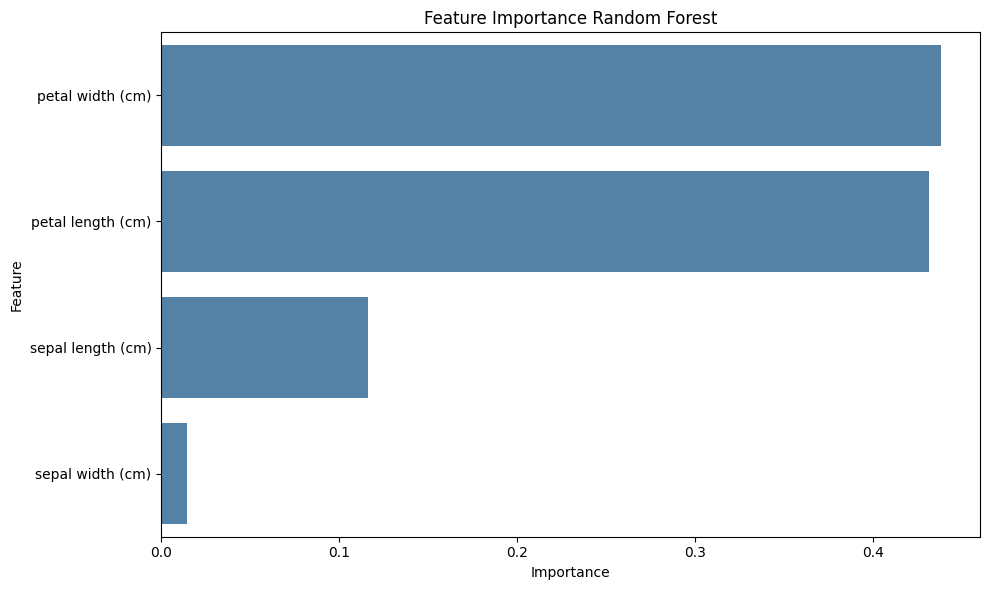

In [16]:
plt.figure(figsize=(10, 6))
sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature",
    color="steelblue"
)
plt.title("Feature Importance Random Forest")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

---
## 7. Catatan Penting Praktikum

- Random Forest = banyak pohon + data acak (bagging) + fitur acak; prediksi lewat voting.
- Random Forest tidak sensitif skala fitur, sehingga scaling umumnya tidak perlu.
- `feature_importances_` adalah proporsi relatif (jumlah = 1), bukan akurasi.
- Satu skor dari satu split tidak cukup untuk menilai model.

---
## 8. Latihan

**Studi Kasus: Klasifikasi Jenis Wine Berdasarkan Analisis Kimia**

Dataset: gunakan dataset `wine` yang tersedia di scikit-learn (`sklearn.datasets.load_wine`).

Seorang data scientist bekerja untuk sebuah perkebunan anggur ternama. Perkebunan ini menghasilkan tiga jenis wine berbeda yang berasal dari kultivar anggur yang sama namun ditanam di area yang berbeda. Tim produksi ingin memahami secara ilmiah senyawa kimia apa yang paling signifikan dalam membedakan ketiga jenis wine ini. Informasi ini akan digunakan untuk standarisasi proses kontrol kualitas dan memastikan setiap jenis wine memiliki karakteristik kimia yang konsisten. Dataset berisi 13 hasil analisis kimia (fitur) dari 3 jenis wine (target).

Dengan menggunakan algoritma Random Forest, lakukan analisis berikut:
1. **Muat dan Eksplorasi Data**
   - Baca dataset wine dari `sklearn.datasets` dan ubah menjadi DataFrame pandas.
   - Tampilkan 10 baris terakhir.
   - *Tips:* jadikan target sebagai `pd.Series` (bukan DataFrame satu kolom) agar tidak muncul `DataConversionWarning` saat `fit`.
2. **Persiapan Data**
   - Definisikan X sebagai fitur (data kimia) dan y sebagai target (jenis wine).
   - Bagi dataset menjadi data latih (80%) dan data uji (20%). Gunakan `random_state=42`. (NB: boleh diubah jika skor akhir lebih baik.)
3. **Latih Model Random Forest**
   - Inisialisasi dan latih model `RandomForestClassifier` pada data latih. Bisa digunakan `n_estimators=100`.
4. **Evaluasi Kinerja Model**
   - Buat prediksi pada data uji dan cetak `classification_report` untuk melihat akurasi, presisi, dan recall model.
5. **Analisis Feature Importance**
   - Ekstrak skor kepentingan fitur (feature importance) dari model yang telah dilatih.
6. **Visualisasikan Hasil**
   - Buat bar plot menggunakan seaborn untuk memvisualisasikan skor feature importance. Urutkan fitur dari yang paling penting hingga yang kurang penting.
7. **Interpretasi dan Rekomendasi**
   - Berdasarkan visualisasi, tiga senyawa kimia apa yang menjadi pembeda utama antar jenis wine?
   - Jika tim produksi ingin melakukan tes kontrol kualitas yang cepat dan hemat biaya dengan hanya mengukur beberapa fitur kunci, fitur mana saja yang sebaiknya direkomendasikan untuk diukur? Jelaskan alasannya.
   - Anggap fitur `proline` dan `flavanoids` memiliki skor tertinggi. Apa artinya ini bagi seorang ahli wine dalam konteks identifikasi produk?

NB: Jawab pertanyaan nomor 7 dalam teks markdown.

### Jawaban Interpretasi dan Rekomendasi

Berdasarkan feature importance, tiga pembeda utama adalah `proline`, `flavanoids`, dan `color_intensity`. Ketiganya layak diprioritaskan untuk kontrol kualitas cepat karena memberikan kontribusi terbesar terhadap keputusan model dalam membedakan jenis wine. Mengukur fitur-fitur tersebut dapat mengurangi jumlah uji awal, tetapi hasilnya tetap perlu dikonfirmasi secara berkala dengan seluruh analisis kimia.

Jika `proline` dan `flavanoids` memiliki skor tertinggi, artinya variasi kadar kedua senyawa tersebut paling informatif untuk memisahkan kultivar pada data ini. Bagi ahli wine, keduanya dapat dipakai sebagai indikator awal identifikasi produk, bukan sebagai bukti tunggal karena feature importance menunjukkan kontribusi prediktif, bukan hubungan sebab-akibat.